# Central Limit Theorem

This notebook accompanies [Central Limit Theorem](../../notes/sampling_and_sampling_distributions/central_limit_theorem.md). We watch the distribution of sample means become normal for a discrete (die) and a strongly skewed (exponential) population, quantify the approximation, and use it for probabilities.

## A die: means for increasing sample size

A fair die has $\mu=3.5$ and $\sigma=\sqrt{35/12}\approx1.708$.

n= 1 mean=3.480 SE sim=1.705 sigma/sqrt n=1.708
n= 2 mean=3.507 SE sim=1.207 sigma/sqrt n=1.208
n= 8 mean=3.505 SE sim=0.604 sigma/sqrt n=0.604
n=32 mean=3.498 SE sim=0.304 sigma/sqrt n=0.302


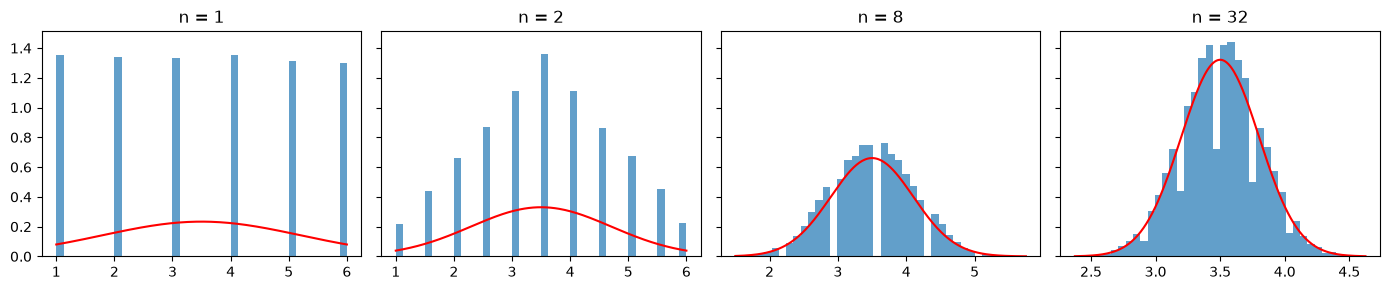

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

rng = np.random.default_rng(42)

sides = np.arange(1, 7)
mu, sigma = sides.mean(), sides.std()
reps = 20_000
fig, axes = plt.subplots(1, 4, figsize=(14, 3), sharey=True)
for ax, n in zip(axes, (1, 2, 8, 32)):
    means = rng.choice(sides, size=(reps, n)).mean(axis=1)
    print(f"n={n:2d} mean={means.mean():.3f} SE sim={means.std(ddof=1):.3f} sigma/sqrt n={sigma/np.sqrt(n):.3f}")
    ax.hist(means, bins=40, density=True, alpha=0.7)
    xs = np.linspace(means.min(), means.max(), 200)
    ax.plot(xs, stats.norm.pdf(xs, mu, sigma / np.sqrt(n)), "r")
    ax.set_title(f"n = {n}")
plt.tight_layout(); plt.show()

## An exponential population

The exponential distribution is strongly right-skewed (skewness 2). The sample mean of $n$ draws has skewness $2/\sqrt n$, so it becomes more symmetric as $n$ grows. The mean of $n$ Exponential(1) draws is exactly Gamma with shape $n$ and scale $1/n$, which lets us compare the normal approximation with the truth. We compute the exact probability of exceeding $\mu+2.5\,\sigma/\sqrt n$, which the normal approximation puts at $0.0062$ for every $n$.

In [2]:
print("Upper-tail probability beyond mu + 2.5 standard errors (normal approx: %.5f)" % stats.norm.sf(2.5))
for n in (5, 30, 100):
    cut = 1 + 2.5 / np.sqrt(n)
    exact_p = stats.gamma(a=n, scale=1 / n).sf(cut)
    print(f"n={n:3d}  cut={cut:.3f}  exact P(xbar > cut) = {exact_p:.5f}")
print("Skewness of xbar (exact):", [round(float(stats.gamma(a=n).stats('s')), 3) for n in (5, 30, 100)])
print("2/sqrt(n):               ", [round(float(2 / np.sqrt(n)), 3) for n in (5, 30, 100)])

Upper-tail probability beyond mu + 2.5 standard errors (normal approx: 0.00621)
n=  5  cut=2.118  exact P(xbar > cut) = 0.01987
n= 30  cut=1.456  exact P(xbar > cut) = 0.01204
n=100  cut=1.250  exact P(xbar > cut) = 0.00938
Skewness of xbar (exact): [0.894, 0.365, 0.2]
2/sqrt(n):                [0.894, 0.365, 0.2]


## Simulating the note's example

1,000 samples of size 50 from an exponential population; the histogram of means is bell-shaped and a normal Q-Q plot is nearly a straight line.

population mean: 0.9957  mean of means: 0.9882
SE sim: 0.135  sigma/sqrt n: 0.1399


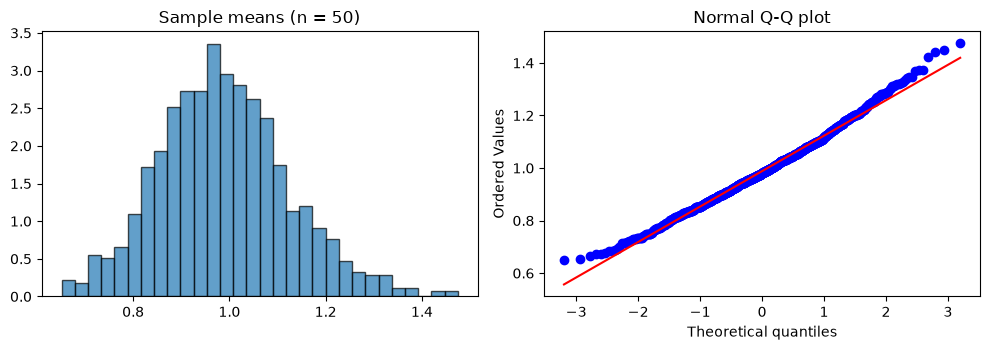

In [3]:
population = rng.exponential(1.0, 10_000)
means = rng.choice(population, size=(1000, 50)).mean(axis=1)
print("population mean:", round(population.mean(), 4), " mean of means:", round(means.mean(), 4))
print("SE sim:", round(means.std(ddof=1), 4), " sigma/sqrt n:", round(population.std() / np.sqrt(50), 4))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
axes[0].hist(means, bins=30, density=True, edgecolor="black", alpha=0.7)
axes[0].set_title("Sample means (n = 50)")
stats.probplot(means, dist="norm", plot=axes[1])
axes[1].set_title("Normal Q-Q plot")
plt.tight_layout(); plt.show()

## Quantifying convergence

The Kolmogorov-Smirnov distance between the standardized sample mean and $N(0,1)$ shrinks as $n$ grows (here for exponential data).

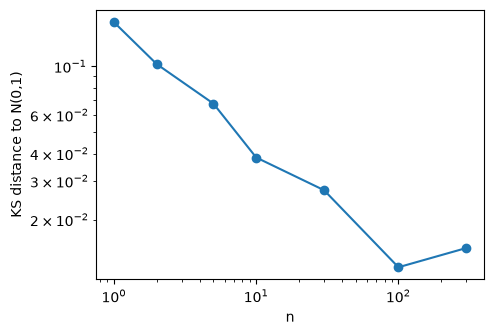

{1: 0.159, 2: 0.102, 5: 0.068, 10: 0.038, 30: 0.027, 100: 0.012, 300: 0.015}


In [4]:
ns = [1, 2, 5, 10, 30, 100, 300]
ks = []
for n in ns:
    z = (rng.exponential(1.0, size=(5000, n)).mean(axis=1) - 1) * np.sqrt(n)
    ks.append(stats.kstest(z, "norm").statistic)
plt.figure(figsize=(5, 3.5))
plt.loglog(ns, ks, "o-")
plt.xlabel("n"); plt.ylabel("KS distance to N(0,1)")
plt.show()
print({n_: round(float(k_), 3) for n_, k_ in zip(ns, ks)})

## Using the CLT for probabilities

(a) Heads in 100 fair tosses: $P(X\ge60)$ exactly and by normal approximation with and without continuity correction. (b) Incomes with $\mu=67{,}000$, $\sigma=38{,}000$, $n=100$: $P(|\bar X-\mu|<5000)$.

In [5]:
exact = stats.binom.sf(59, 100, 0.5)
no_cc = stats.norm.sf(60, 50, 5)
with_cc = stats.norm.sf(59.5, 50, 5)
print(f"P(heads >= 60): exact={exact:.4f}  normal={no_cc:.4f}  normal+cc={with_cc:.4f}")

se = 38_000 / np.sqrt(100)
print("P(|xbar - mu| < 5000) =", round(2 * stats.norm.cdf(5000 / se) - 1, 4))

# n needed for sigma = 6 so that xbar is within 1 of mu with prob >= 0.95
print("n needed:", int(np.ceil((stats.norm.ppf(0.975) * 6 / 1) ** 2)))

P(heads >= 60): exact=0.0284  normal=0.0228  normal+cc=0.0287
P(|xbar - mu| < 5000) = 0.8118
n needed: 139
